# Regime sweep: when does skipping hubs help GOAT?

The hub test showed that GOAT does better on Chung–Lu and PAPER when the 10 biggest hubs are skipped, and that the hubs' wrong edges are the problem. This sweep asks where that holds, using fresh Chung–Lu pairs (n = 600, mean degree 16).

**Settings**
- **Tail weight:** the Pareto shape α of the Chung–Lu weights. α = 2 is round 1's heavy tail, with hubs of degree up to about 100. α = 3 is milder (up to about 75), and α = 6 is close to ER (up to about 30).
- **Noise:** ρ, the edge correlation between A and B, at 0.40, 0.45 (round 1), 0.50 and 0.55. GOAT's transition is steep. In a calibration with 2 pairs per setting, no rule succeeded with 40 seeds at ρ = 0.35, and every rule needed a single seed at 0.60 and 0.75.
- **Rules:** top degree, hub-free top degree (top degree without its first 10 picks) and random.
- **Pairs:** 10 fresh pairs per setting.
- **GOAT:** round 1's Chung–Lu settings (regulariser 300).

**Query, run, check, stop.** For each pair and rule, budgets go up a ladder (1, 2, 3, 4, 6, 8, 10, 12, 14, 17, 20, 24, 28, 34, 40). The first success ends the search, so each search gives the number of queries needed. A search that never succeeds counts as 46.

**Predictions** (written before the run)
- The saving from skipping hubs grows with heavier tails, since the hubs are bigger and give more wrong hints.
- It grows with more noise (lower ρ), since a larger share of each hub's edges is wrong.
- It shrinks toward the light tail, where the 10 highest-degree vertices are not really hubs. At the low-noise end (0.50–0.55) it may reverse, because reliable hubs are the best seeds of all.

**Run time.** About 45–75 minutes with 3 pairs at a time; the noisiest settings take longest. Each pair is saved when it finishes, so rerunning resumes.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

from selection_rule_comparison.archive import regime_sweep as R

RUN_EXPERIMENTS = True   # False: only analyse saved results
ALGORITHM = 'goat'
COLORS = {'top_degree': '#222222', 'hub_free_top_degree': '#FF7F0E', 'random': '#9E9E9E'}
TAIL_LABELS = {2.0: 'α = 2\n(heavy tail)', 3.0: 'α = 3', 6.0: 'α = 6\n(light tail)'}

## Run

Progress prints below, one line per pair; settings with more noise take longer. You can also run it in a terminal from the repository root: `python -m selection_rule_comparison.regime_sweep`.

In [2]:
if RUN_EXPERIMENTS:
    R.run_all(jobs=3)

01:22:16 120 pairs to run, 3 at a time: roughly 56 minutes (harder settings take longer).
01:29:42 [1/120] goat alpha2.0_rho0.40 pair 2: 32 runs in 438 s
01:30:05 [2/120] goat alpha2.0_rho0.40 pair 0: 33 runs in 461 s
01:31:02 [3/120] goat alpha2.0_rho0.40 pair 1: 37 runs in 519 s
01:40:19 [4/120] goat alpha2.0_rho0.40 pair 3: 28 runs in 637 s
01:40:48 [5/120] goat alpha2.0_rho0.40 pair 4: 31 runs in 644 s
01:44:08 [6/120] goat alpha2.0_rho0.40 pair 5: 35 runs in 785 s
01:48:51 [7/120] goat alpha2.0_rho0.40 pair 6: 35 runs in 513 s
01:51:32 [8/120] goat alpha2.0_rho0.40 pair 7: 36 runs in 643 s
01:53:36 [9/120] goat alpha2.0_rho0.40 pair 8: 37 runs in 568 s
01:56:52 [10/120] goat alpha2.0_rho0.40 pair 9: 37 runs in 481 s
01:59:49 [11/120] goat alpha3.0_rho0.40 pair 0: 44 runs in 497 s
02:00:33 [12/120] goat alpha3.0_rho0.40 pair 1: 36 runs in 418 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.06458841318994177 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


02:03:42 [13/120] goat alpha3.0_rho0.40 pair 2: 39 runs in 410 s
02:07:39 [14/120] goat alpha3.0_rho0.40 pair 3: 44 runs in 470 s
02:07:53 [15/120] goat alpha3.0_rho0.40 pair 4: 40 runs in 440 s
02:11:38 [16/120] goat alpha3.0_rho0.40 pair 5: 44 runs in 476 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.09438639672891816 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


02:14:59 [17/120] goat alpha3.0_rho0.40 pair 6: 41 runs in 440 s
02:15:49 [18/120] goat alpha3.0_rho0.40 pair 7: 42 runs in 476 s
02:19:11 [19/120] goat alpha3.0_rho0.40 pair 8: 44 runs in 453 s
02:21:19 [20/120] goat alpha3.0_rho0.40 pair 9: 39 runs in 380 s
02:24:05 [21/120] goat alpha6.0_rho0.40 pair 0: 45 runs in 495 s
02:26:36 [22/120] goat alpha6.0_rho0.40 pair 1: 44 runs in 445 s
02:29:34 [23/120] goat alpha6.0_rho0.40 pair 2: 44 runs in 495 s
02:31:04 [24/120] goat alpha6.0_rho0.40 pair 3: 41 runs in 419 s
02:33:43 [25/120] goat alpha6.0_rho0.40 pair 4: 43 runs in 428 s
02:36:52 [26/120] goat alpha6.0_rho0.40 pair 5: 44 runs in 438 s
02:38:31 [27/120] goat alpha6.0_rho0.40 pair 6: 43 runs in 447 s
02:41:19 [28/120] goat alpha6.0_rho0.40 pair 7: 44 runs in 455 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.08933671958757808 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


02:44:07 [29/120] goat alpha6.0_rho0.40 pair 8: 45 runs in 435 s
02:44:20 [30/120] goat alpha2.0_rho0.45 pair 0: 18 runs in 181 s
02:45:36 [31/120] goat alpha6.0_rho0.40 pair 9: 45 runs in 425 s
02:46:49 [32/120] goat alpha2.0_rho0.45 pair 1: 17 runs in 162 s
02:48:17 [33/120] goat alpha2.0_rho0.45 pair 3: 23 runs in 161 s
02:48:37 [34/120] goat alpha2.0_rho0.45 pair 2: 27 runs in 258 s
02:49:45 [35/120] goat alpha2.0_rho0.45 pair 4: 26 runs in 176 s
02:51:12 [36/120] goat alpha2.0_rho0.45 pair 6: 22 runs in 154 s
02:51:27 [37/120] goat alpha2.0_rho0.45 pair 5: 24 runs in 190 s
02:52:33 [38/120] goat alpha2.0_rho0.45 pair 7: 23 runs in 168 s
02:53:33 [39/120] goat alpha2.0_rho0.45 pair 9: 20 runs in 126 s
02:53:42 [40/120] goat alpha2.0_rho0.45 pair 8: 26 runs in 151 s
02:56:34 [41/120] goat alpha3.0_rho0.45 pair 0: 33 runs in 241 s
02:56:59 [42/120] goat alpha3.0_rho0.45 pair 1: 31 runs in 206 s
02:57:29 [43/120] goat alpha3.0_rho0.45 pair 2: 34 runs in 226 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.08969499033762038 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


02:58:49 [44/120] goat alpha3.0_rho0.45 pair 3: 30 runs in 135 s
02:59:51 [45/120] goat alpha3.0_rho0.45 pair 4: 33 runs in 171 s
03:00:09 [46/120] goat alpha3.0_rho0.45 pair 5: 34 runs in 160 s
03:01:32 [47/120] goat alpha3.0_rho0.45 pair 6: 35 runs in 163 s
03:02:22 [48/120] goat alpha3.0_rho0.45 pair 7: 31 runs in 151 s
03:02:44 [49/120] goat alpha3.0_rho0.45 pair 8: 34 runs in 155 s
03:03:40 [50/120] goat alpha3.0_rho0.45 pair 9: 26 runs in 128 s


/Users/langsong/miniforge3/envs/ds/lib/python3.11/site-packages/graspologic/match/solver.py:383: UserWarning: Sinkhorn-Knopp algorithm for solving linear sum transport problem did not converge. The final error was 0.1313803181321035 and the `transport_tol` was 0.05. You may want to consider increasing `transport_regularizer`, increasing `transport_max_iter`, or this could be the result of `transport_tol` set too small.
  warnings.warn(


03:05:17 [51/120] goat alpha6.0_rho0.45 pair 0: 38 runs in 175 s
03:05:52 [52/120] goat alpha6.0_rho0.45 pair 1: 36 runs in 188 s
03:06:41 [53/120] goat alpha6.0_rho0.45 pair 2: 38 runs in 181 s
03:08:16 [54/120] goat alpha6.0_rho0.45 pair 3: 35 runs in 179 s
03:08:43 [55/120] goat alpha6.0_rho0.45 pair 4: 34 runs in 171 s
03:09:59 [56/120] goat alpha6.0_rho0.45 pair 5: 39 runs in 198 s
03:11:34 [57/120] goat alpha6.0_rho0.45 pair 7: 36 runs in 171 s
03:11:36 [58/120] goat alpha6.0_rho0.45 pair 6: 37 runs in 200 s
03:12:08 [59/120] goat alpha2.0_rho0.50 pair 0: 9 runs in 32 s
03:12:45 [60/120] goat alpha6.0_rho0.45 pair 8: 33 runs in 166 s
03:13:24 [61/120] goat alpha2.0_rho0.50 pair 1: 17 runs in 76 s
03:13:53 [62/120] goat alpha2.0_rho0.50 pair 2: 12 runs in 68 s
03:14:20 [63/120] goat alpha2.0_rho0.50 pair 3: 11 runs in 56 s
03:14:23 [64/120] goat alpha2.0_rho0.50 pair 5: 3 runs in 3 s
03:14:34 [65/120] goat alpha6.0_rho0.45 pair 9: 35 runs in 181 s
03:14:48 [66/120] goat alpha2.0_r

## 1. The graphs

Each row is one setting, averaged over its pairs. "Hub degree" is the mean degree of the 10 highest-degree vertices. "Edges kept" is the share of A's edges that are also in B, overall and for the 10 hubs.

In [3]:
runs = R.load_runs()
runs = runs[runs['algorithm'] == ALGORITHM]
queries = R.queries_needed(runs)

graphs = (runs.groupby(['alpha', 'rho', 'pair_index'])[['mean_degree', 'max_degree', 'hub_mean_degree', 'edges_kept',
                                                       'hub_edges_kept']].first()
          .groupby(['alpha', 'rho']).mean())
graphs['pairs'] = runs.groupby(['alpha', 'rho'])['pair_index'].nunique()
graphs.columns = ['mean degree', 'max degree', 'hub degree', 'edges kept', 'hub edges kept', 'pairs']
display(graphs.round(2))

mean degree  max degree  hub degree  edges kept  hub edges kept  \
alpha rho                                                                     
2.0   0.40        15.93       105.9       71.35        0.43            0.50   
      0.45        15.97       106.0       71.25        0.48            0.53   
      0.50        16.03        98.8       70.04        0.53            0.59   
      0.55        16.01        99.6       70.76        0.57            0.62   
3.0   0.40        15.96        73.6       44.81        0.42            0.43   
      0.45        15.85        73.0       43.27        0.46            0.49   
      0.50        16.13        72.9       43.76        0.52            0.53   
      0.55        15.96        71.8       43.87        0.57            0.58   
6.0   0.40        16.16        34.2       29.19        0.41            0.42   
      0.45        15.90        33.1       28.47        0.47            0.47   
      0.50        15.91        34.4       28.54        0.52            0.51   
      0.55        15.97        36.7       29.13        0.56            0.56   

            pairs  
alpha rho          
2.0   0.40     10  
      0.45     10  
      0.50     10  
      0.55     10  
3.0   0.40     10  
      0.45     10  
      0.50     10  
      0.55     10  
6.0   0.40     10  
      0.45     10  
      0.50     10  
      0.55     10

## 2. Queries saved by skipping hubs

This is the main result. Each point is the mean, over pairs, of top degree's queries minus hub-free top degree's. The bars are 95% bootstrap intervals over pairs.
- **Above zero:** skipping hubs saves queries.
- **Below zero:** top degree is better.

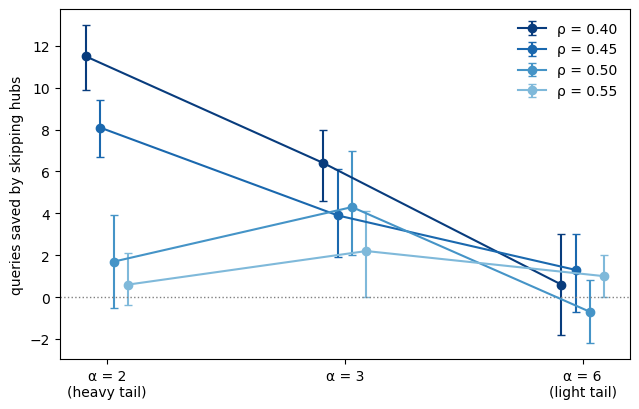

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
alphas = sorted(queries['alpha'].unique())
rhos = sorted(queries['rho'].unique())
rho_colors = dict(zip(rhos, plt.cm.Blues(np.linspace(0.95, 0.45, len(rhos)))))   # darker = noisier
done = set(zip(queries['alpha'], queries['rho']))
for i, rho in enumerate(rhos):
    cells = [(j, alpha) for j, alpha in enumerate(alphas) if (alpha, rho) in done]
    points = [R.compare(queries, ALGORITHM, alpha, rho, 'top_degree', 'hub_free_top_degree') for _, alpha in cells]
    x = np.array([j for j, _ in cells]) + (i - (len(rhos) - 1) / 2) * 0.06
    mean = np.array([p['mean'] for p in points])
    ax.errorbar(x, mean, yerr=[mean - [p['low'] for p in points], [p['high'] for p in points] - mean],
                marker='o', capsize=3, color=rho_colors[rho], label=f'ρ = {rho:.2f}')
ax.axhline(0, color='grey', linewidth=1, linestyle=':')
ax.set_xticks(range(len(alphas)))
ax.set_xticklabels([TAIL_LABELS.get(a, f'α = {a:g}') for a in alphas])
ax.set_ylabel('queries saved by skipping hubs')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Queries needed by each rule

There is one panel per noise level. Each point is the mean number of queries needed (lower is better), with 95% bootstrap intervals over pairs.

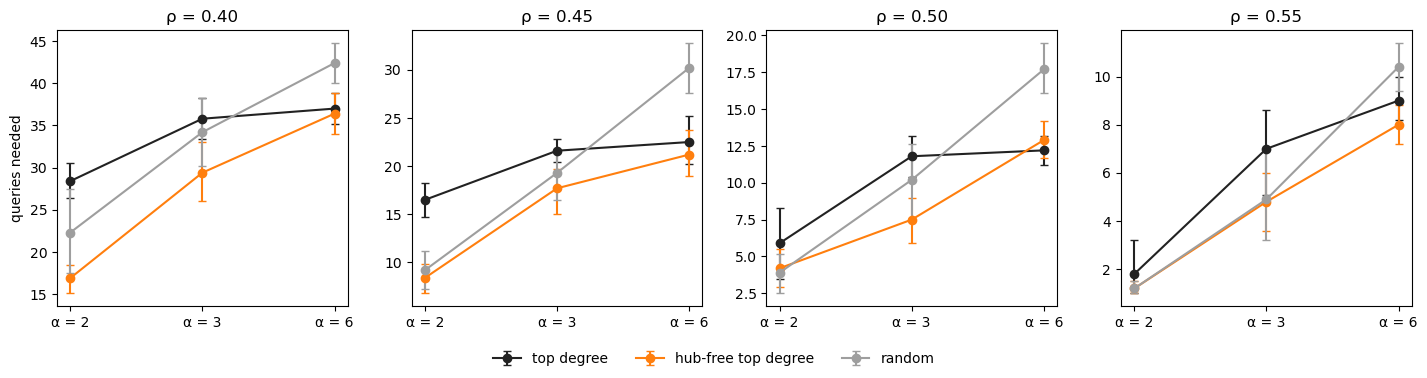

In [5]:
fig, axes = plt.subplots(1, len(rhos), figsize=(3.6 * len(rhos), 3.8), squeeze=False)
boot_rng = np.random.default_rng(2026)
for ax, rho in zip(axes[0], rhos):
    for rule in R.RULES:
        xs, means, lows, highs = [], [], [], []
        for j, alpha in enumerate(alphas):
            values = queries[np.isclose(queries['alpha'], alpha) & np.isclose(queries['rho'], rho)
                             & (queries['rule'] == rule)]['queries'].to_numpy(float)
            if len(values) == 0:
                continue
            boot = boot_rng.choice(values, size=(2000, len(values))).mean(axis=1)
            xs.append(j)
            means.append(values.mean())
            lows.append(np.percentile(boot, 2.5))
            highs.append(np.percentile(boot, 97.5))
        means = np.array(means)
        ax.errorbar(xs, means, yerr=[means - lows, np.array(highs) - means], marker='o',
                    capsize=3, color=COLORS[rule], label=R.LABELS[rule])
    ax.set_title(f'ρ = {rho:.2f}')
    ax.set_xticks(range(len(alphas)))
    ax.set_xticklabels([f'α = {a:g}' for a in alphas])
axes[0, 0].set_ylabel('queries needed')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## 4. Pair-by-pair comparisons

Hub-free top degree against top degree in each setting. The columns are:
- **fewer / same / more:** pairs where hub-free top degree needs fewer, the same or more queries;
- **p:** a sign test;
- **mean change:** hub-free minus top degree, with a 95% bootstrap interval (negative = fewer queries);
- **never succeeded:** searches that reached the top of the ladder without success, for each rule.

In [6]:
rows = []
for alpha in alphas:
    for rho in rhos:
        if (alpha, rho) not in done:
            continue
        c = R.compare(queries, ALGORITHM, alpha, rho, 'hub_free_top_degree', 'top_degree')
        cell = queries[np.isclose(queries['alpha'], alpha) & np.isclose(queries['rho'], rho)]
        never = cell.groupby('rule')['never'].sum()
        rows.append({'α': alpha, 'ρ': rho, 'pairs': c['pairs'], 'fewer': c['fewer'], 'same': c['same'],
                     'more': c['more'], 'p': c['p'],
                     'mean change': f"{c['mean']:+.1f} [{c['low']:+.1f}, {c['high']:+.1f}]",
                     'never succeeded (top degree / hub-free / random)':
                         f"{never.get('top_degree', 0)} / {never.get('hub_free_top_degree', 0)} / {never.get('random', 0)}"})
display(pd.DataFrame(rows).set_index(['α', 'ρ']).round(3))

pairs  fewer  same  more      p          mean change  \
α   ρ                                                            
2.0 0.40     10     10     0     0  0.002  -11.5 [-13.0, -9.9]   
    0.45     10     10     0     0  0.002    -8.1 [-9.4, -6.7]   
    0.50     10      5     3     2  0.453    -1.7 [-3.9, +0.5]   
    0.55     10      2     6     2  1.000    -0.6 [-2.1, +0.4]   
3.0 0.40     10      9     1     0  0.004    -6.4 [-8.0, -4.6]   
    0.45     10      7     3     0  0.016    -3.9 [-6.1, -1.9]   
    0.50     10      7     3     0  0.016    -4.3 [-7.0, -2.0]   
    0.55     10      8     0     2  0.109    -2.2 [-4.1, +0.0]   
6.0 0.40     10      3     5     2  1.000    -0.6 [-3.0, +1.8]   
    0.45     10      6     2     2  0.289    -1.3 [-3.0, +0.7]   
    0.50     10      4     1     5  1.000    +0.7 [-0.8, +2.2]   
    0.55     10      5     4     1  0.219    -1.0 [-2.0, +0.0]   

         never succeeded (top degree / hub-free / random)  
α   ρ                                                      
2.0 0.40                                        0 / 0 / 0  
    0.45                                        0 / 0 / 0  
    0.50                                        0 / 0 / 0  
    0.55                                        0 / 0 / 0  
3.0 0.40                                        0 / 0 / 1  
    0.45                                        0 / 0 / 0  
    0.50                                        0 / 0 / 0  
    0.55                                        0 / 0 / 0  
6.0 0.40                                        0 / 0 / 5  
    0.45                                        0 / 0 / 0  
    0.50                                        0 / 0 / 0  
    0.55                                        0 / 0 / 0